In [1]:
import re
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
from scipy.stats import norm
from scipy.stats import moyal

In [2]:
PLOTS_DIR = Path("plots")
PLOTS_DIR.mkdir(exist_ok=True)

def save_plot(filename=None):
    figure = plt.gcf()
    if filename is None:
        title = figure.axes[0].get_title() if figure.axes else "plot"
        filename = re.sub(
            r"[^a-zA-Z0-9_-]+",
            "_",
            title
        ).strip("_").lower()
        filename = filename or "plot"

    figure.savefig(
        PLOTS_DIR / f"{filename}.png",
        dpi=300,
        bbox_inches="tight"
    )

In [4]:
CSV_PATH = "../data_1000e.csv"

COLUMN_NAMES = [
    "RunID",
    "EventID",
    "TrackID",
    "Hit",
    "GlobalTime",
    "TimeSinceZero",
    "TrackLenght",
    "PhotonEnergy",
    "PhotonFlightTime",
    "PhotonCreationTime",
    "Process",
    "NSideReflections",
    "ScintillatorLenght",
    "EmissionAngle"
]

DTYPES = {
    "RunID": "int32",
    "EventID": "int32",
    "TrackID": "int32",
    "Hit": "category",
    "GlobalTime": "float64",
    "TimeSinceZero": "float64",
    "TrackLenght": "float32",
    "PhotonEnergy": "float32",
    "PhotonFlightTime": "float32",
    "PhotonCreationTime": "float32",
    "Process": "category",
    "NSideReflections": "int32",
    "ScintillatorLenght": "float32",
    "EmissionAngle": "float32",
}

data = pd.read_csv(CSV_PATH, comment="#", header=None, names=COLUMN_NAMES, dtype=DTYPES)

counts_data = len(data)
counts_events = data['EventID'].nunique()

print(f"{counts_data:,} Photon-Treffer geladen, {counts_events:,} Events")
data.head()

data["WavelengthNM"] = (1239.841984 / data["PhotonEnergy"])

print("CSV File loaded!")

1,636,193 Photon-Treffer geladen, 1,000 Events
CSV File loaded!


In [5]:
# masks
mask_process_scintillation = data["Process"] == "Scintillation"
mask_process_cerenkov = data["Process"] == "Cerenkov"

mask_hit_top = data["Hit"] == "top"
mask_hit_bottom = data["Hit"] == "bottom"

# all data
data_all = data.copy()

# only Scintillation
data_all_scintillation = data[
    mask_process_scintillation
].copy()

# only Cerenkov
data_all_cerenkov = data[
    mask_process_cerenkov
].copy()

# only top data all
data_all_top = data[
    mask_hit_top
].copy()

# only top data scintillation
data_all_top_scintillation = data[
    (mask_hit_top)
    &
    (mask_process_scintillation)
].copy()

# only top data cerenkov
data_all_top_cerenkov = data[
    (mask_hit_top)
    &
    (mask_process_cerenkov)
].copy()

# only bottom data all
data_all_bottom = data[
    mask_hit_bottom
].copy()

# only bottom data scintillation
data_all_bottom_scintillation = data[
    (mask_hit_bottom)
    &
    (mask_process_scintillation)
].copy()

# only top data cerenkov
data_all_bottom_cerenkov = data[
    (mask_hit_bottom)
    &
    (mask_process_cerenkov)
].copy()

# arrival times
data_arr_times_all = (
    data_all["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_scintillation = (
    data_all_scintillation["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_cerenkov = (
    data_all_cerenkov["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_top = (
    data_all_top["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_all_bottom = (
    data_all_bottom["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_top_scintillation = (
    data_all_top_scintillation["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_top_cerenkov = (
    data_all_top_cerenkov["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_bottom_scintillation = (
    data_all_bottom_scintillation["TimeSinceZero"].dropna().to_numpy()
)

data_arr_times_bottom_cerenkov = (
    data_all_bottom_cerenkov["TimeSinceZero"].dropna().to_numpy()
)

data_wavelength_all = (
    data_all["WavelengthNM"].dropna().to_numpy()
)

data_wavelength_scintillation = (
    data_all_scintillation["WavelengthNM"].dropna().to_numpy()
)

data_wavelength_cerenkov = (
    data_all_cerenkov["WavelengthNM"].dropna().to_numpy()
)

# creat groups for every event: access via event17 = events[17]
data_events = {
    event_id: event_data.copy()
    for event_id, event_data in data.groupby("EventID")
}

print("Data loaded!")

Data loaded!


In [6]:
def gauss(x, mean, sigma):
    return 1/(sigma * np.sqrt(2 * np.pi)) * np.exp(- (x - mean)**2 / (2 * sigma**2))

def fit_gauss(times, bins="auto"):
    # Gauss-Fit (def gauss) an das normierte Histogramm der Schwellenzeiten
    hist, edges = np.histogram(times, bins=bins, density=True)
    centers = 0.5 * (edges[:-1] + edges[1:])

    p0 = [np.mean(times), np.std(times, ddof=1)]
    try:
        popt, _ = curve_fit(gauss, centers, hist, p0=p0)
    except (RuntimeError, ValueError):
        return np.nan, np.nan

    return popt[0], abs(popt[1])

def compute_threshold_times(df, thresholds):
    # Zeit, zu der das N-te Photon pro Event eintrifft
    rows = []

    for event_id, event_data in df.groupby("EventID"):
        event_times = event_data["TimeSinceZero"].dropna().to_numpy(dtype=float)
        event_times = np.sort(event_times[event_times >= 0])

        row = {"EventID": event_id, "NPhotons": len(event_times)}

        for threshold in thresholds:
            row[f"threshold_{threshold}"] = (
                event_times[threshold - 1]
                if len(event_times) >= threshold
                else np.nan
            )

        rows.append(row)

    return pd.DataFrame(rows)

def compute_threshold_statistics(times_df, thresholds):
    # Berechnung der statistischen Kenngrößen für die Schwellenzeiten
    rows = []

    for threshold in thresholds:
        times = times_df[f"threshold_{threshold}"].dropna().to_numpy(dtype=float)

        if len(times) > 1:
            gauss_mean, gauss_sigma = fit_gauss(times)
            mean_time = np.mean(times)
            sigma_time = np.std(times, ddof=1)
        else:
            mean_time = sigma_time = gauss_mean = gauss_sigma = np.nan

        rows.append({
            "Threshold": threshold,
            "Events": len(times),
            "MeanTime_ns": mean_time,
            "Sigma_ps": sigma_time * 1000,
            "GaussianMean_ns": gauss_mean,
            "GaussianSigma_ps": gauss_sigma * 1000,
        })

    return pd.DataFrame(rows)

In [21]:
data_all_scintillation

,RunID,EventID,TrackID,Hit,GlobalTime,TimeSinceZero,TrackLenght,PhotonEnergy,PhotonFlightTime,PhotonCreationTime,Process,NSideReflections,ScintillatorLenght,EmissionAngle,WavelengthNM
0,0,0,3313,bottom,3.606160,3.279270,54.445099,3.57951,0.198309,3.080960,Scintillation,5,100.0,71.893303,346.371988
1,0,0,3311,bottom,2.674380,2.347490,126.900002,3.29389,0.425326,1.922160,Scintillation,25,100.0,125.195000,376.406615
2,0,0,3310,bottom,3.341270,3.014380,72.795799,3.45716,0.256301,2.758080,Scintillation,12,100.0,60.799301,358.630201
3,0,0,3307,bottom,3.664880,3.337990,255.686996,3.37452,0.862644,2.475340,Scintillation,55,100.0,48.422600,367.412835
4,0,0,3304,bottom,0.846896,0.520006,69.642197,3.36494,0.241093,0.278913,Scintillation,9,100.0,108.592003,368.458876
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1636186,0,999,4461,bottom,1.640680,1.313790,97.227898,3.39981,0.324755,0.989035,Scintillation,21,100.0,43.361099,364.679778
1636187,0,999,4457,bottom,1.669450,1.342560,62.562698,3.35224,0.233331,1.109230,Scintillation,6,100.0,108.059998,369.854769
1636188,0,999,4455,top,4.660740,4.333850,57.322498,3.40446,0.207062,4.126790,Scintillation,6,100.0,118.497002,364.181691
1636189,0,999,4448,top,2.501290,2.174400,64.319504,2.75024,0.218018,1.956380,Scintillation,5,100.0,85.356903,450.812273


In [48]:
cumulative_photon_thresholds = [
    1, 5, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 150, 200, 220, 250, 300
]

def threshold_table(side_data):
    # Schwellenzeiten pro Event, Spalten = Schwelle
    table = compute_threshold_times(side_data, cumulative_photon_thresholds).set_index("EventID")
    table = table.drop(columns="NPhotons")
    table.columns = cumulative_photon_thresholds
    return table

threshold_top = threshold_table(data_all_top_scintillation)
threshold_bottom = threshold_table(data_all_bottom_scintillation)

# Events ohne Treffer auf einer Seite bleiben als NaN erhalten
threshold_bottom = threshold_bottom.reindex(threshold_top.index.union(threshold_bottom.index))
threshold_top = threshold_top.reindex(threshold_bottom.index)

threshold_times = pd.concat(
    {
        "Top": threshold_top,
        "Bottom": threshold_bottom,
        "Difference": threshold_top - threshold_bottom,
    },
    axis=1,
)

# Zugriff: threshold_times["Top"][50], threshold_times["Difference"][50], threshold_times.loc[event_id]
threshold_times.head()


Top                                                              \
              1         5         10        20        30        40        50    
EventID                                                                         
0        0.268286  0.333509  0.357320  0.398022  0.442833  0.472504  0.503012   
1        0.248110  0.280392  0.355458  0.392974  0.459394  0.525995  0.575179   
2        0.242153  0.273526  0.295337  0.389332  0.422771  0.439945  0.479490   
3        0.266962  0.317208  0.362475  0.434828  0.477283  0.540441  0.588943   
4        0.264138  0.344543  0.398316  0.512671  0.533736  0.566995  0.610817   

                                       ... Difference                      \
              60        70        80   ...        80        90        100   
EventID                                ...                                  
0        0.540218  0.578248  0.616405  ...   0.028814  0.029196  0.011954   
1        0.622988  0.655908  0.720527  ...  -0.028464 -0.015411 -0.041418   
2        0.505423  0.526758  0.550479  ...   0.005709  0.004877  0.011090   
3        0.639130  0.692469  0.716591  ...  -0.004327  0.016106  0.017747   
4        0.657419  0.730108  0.773284  ...   0.108091  0.103413  0.084182   

                                                                               
              110       120       150       200       220       250       300  
EventID                                                                        
0        0.010895  0.006252 -0.009102  0.029660  0.042565  0.021710  0.054230  
1       -0.026568 -0.044907 -0.001070 -0.002630 -0.033910 -0.007740  0.035810  
2        0.015651 -0.016934 -0.005225 -0.027837 -0.019590 -0.018478 -0.052864  
3        0.015007  0.005926  0.015035 -0.062000 -0.089480 -0.156580 -0.197400  
4        0.077174  0.077647  0.050673  0.020130  0.034020  0.041840  0.004310  

[5 rows x 57 columns]

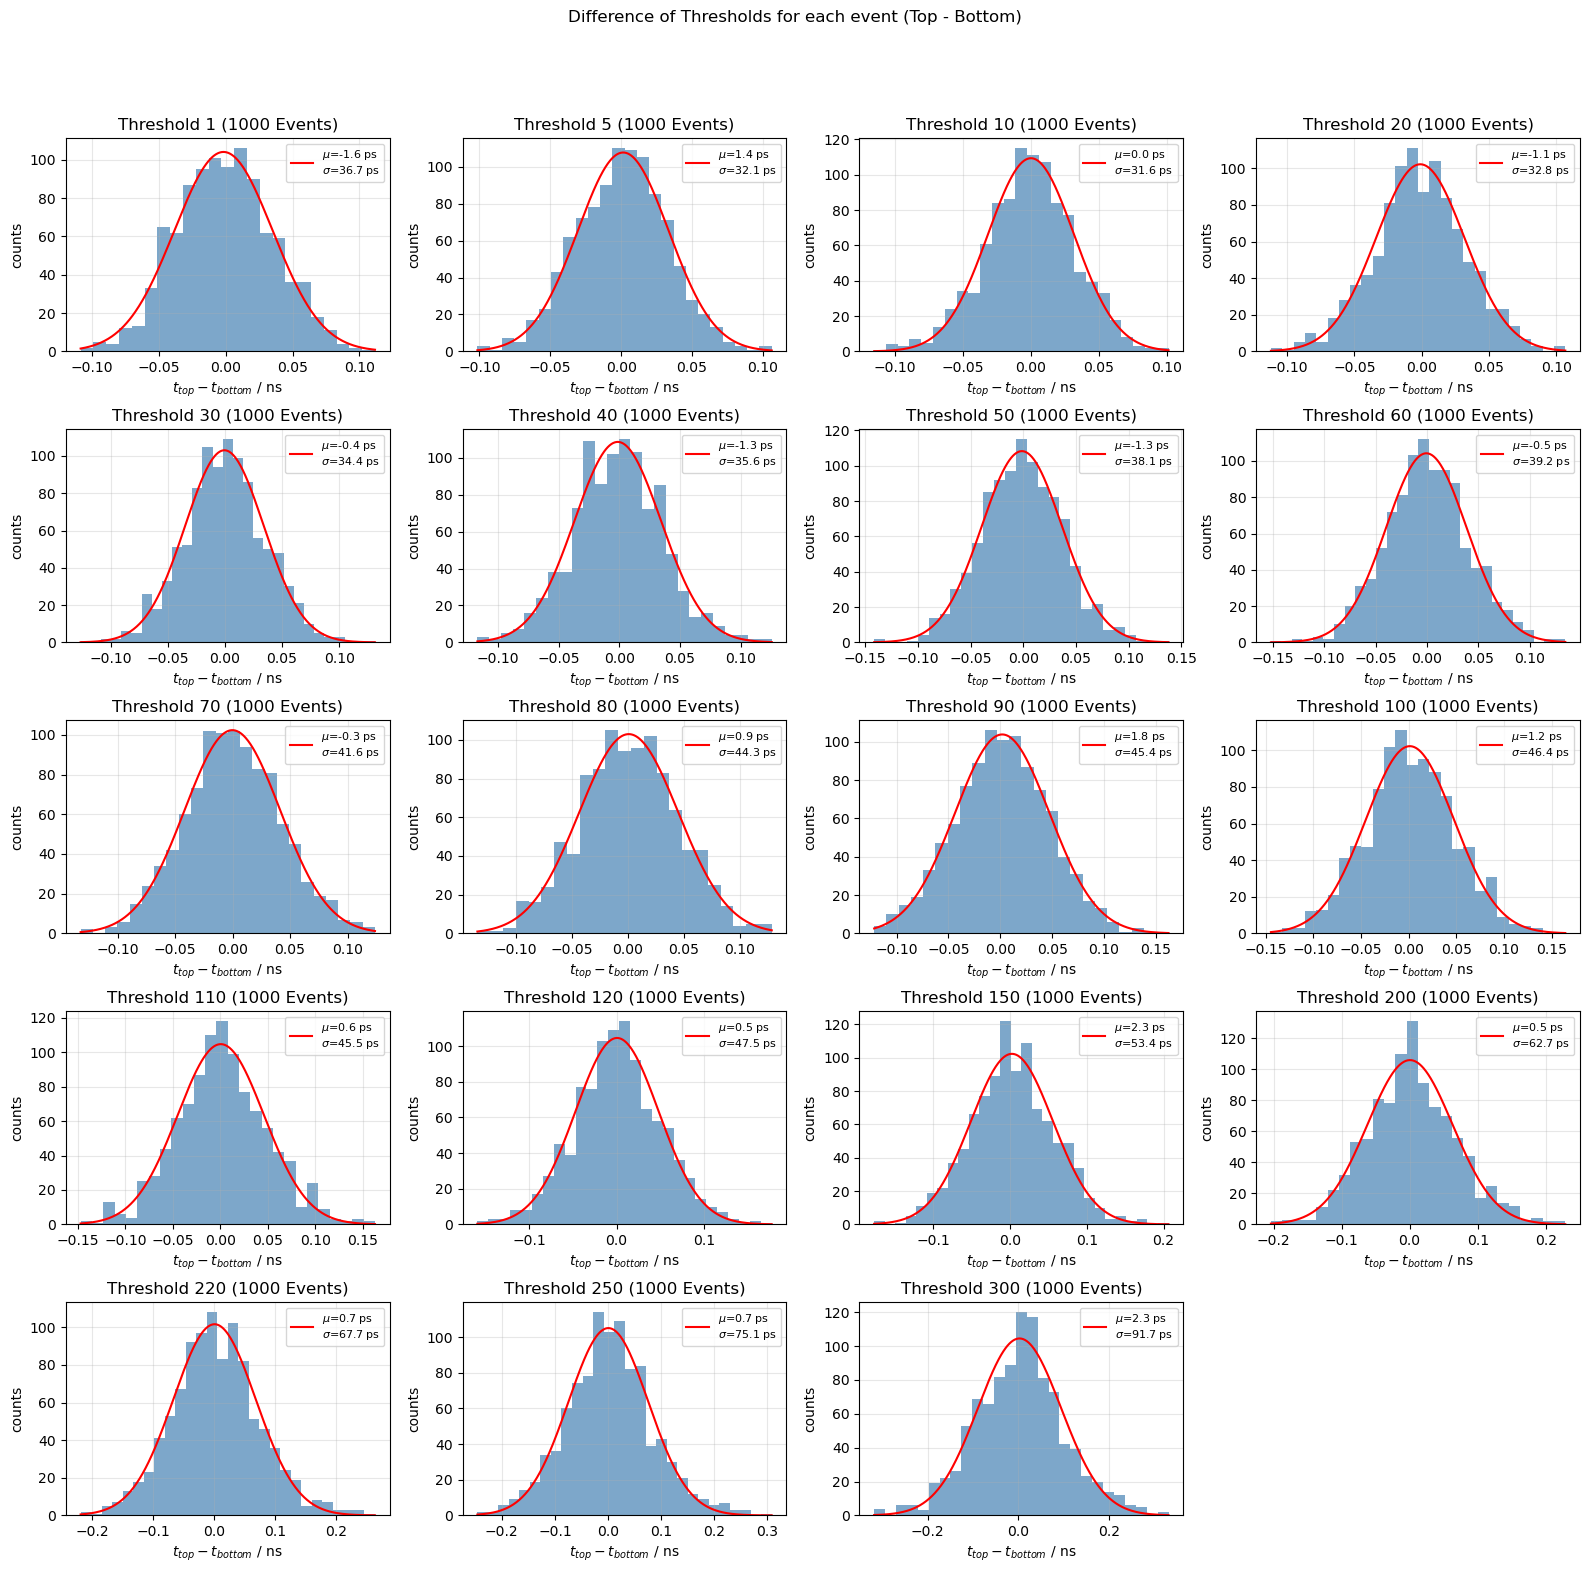

In [49]:
n_cols = 4
n_rows = int(np.ceil(len(cumulative_photon_thresholds) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.2 * n_rows))
axes = axes.ravel()

for ax, threshold in zip(axes, cumulative_photon_thresholds):
    diff = threshold_times["Difference"][threshold].dropna().to_numpy(dtype=float)

    edges = np.histogram_bin_edges(diff, bins="auto")
    bin_width = edges[1] - edges[0]
    ax.hist(diff, bins=edges, color="steelblue", alpha=0.7)

    if len(diff) > 1:
        fit_mean, fit_sigma = fit_gauss(diff)
        if np.isfinite(fit_mean):
            x = np.linspace(diff.min(), diff.max(), 500)
            ax.plot(x, len(diff) * bin_width * gauss(x, fit_mean, fit_sigma), color="red",
                    label=f"$\\mu$={fit_mean * 1000:.1f} ps\n$\\sigma$={fit_sigma * 1000:.1f} ps")
            ax.legend(fontsize=8)

    ax.set_title(f"Threshold {threshold} ({len(diff)} Events)")
    ax.set_xlabel("$t_{top} - t_{bottom}$ / ns")
    ax.set_ylabel("counts")

for ax in axes[len(cumulative_photon_thresholds):]:
    ax.set_visible(False)

fig.suptitle("Difference of Thresholds for each event (Top - Bottom)")
fig.tight_layout()
fig.subplots_adjust(top=0.9)
for ax in axes[:len(cumulative_photon_thresholds)]:
    ax.grid(alpha=0.3)

save_plot("threshold_difference_histograms")

plt.show()

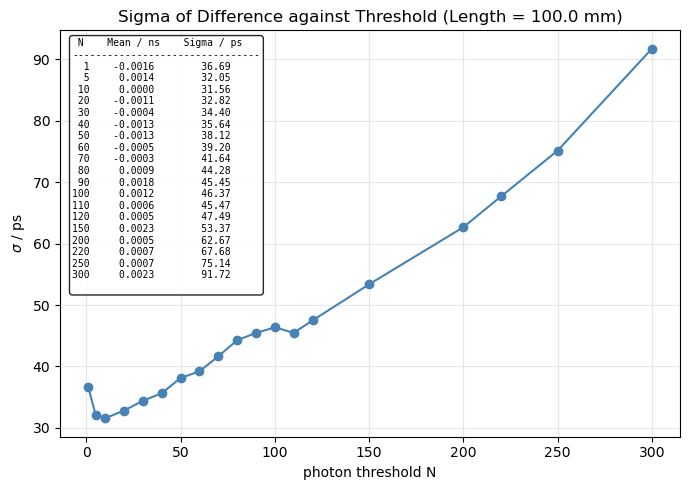

' Threshold  Events  Mean_ns  Sigma_ps  BinWidth_ns\n         1    1000  -0.0016   36.6874       0.0096\n         5    1000   0.0014   32.0516       0.0086\n        10    1000   0.0000   31.5646       0.0086\n        20    1000  -0.0011   32.8204       0.0084\n        30    1000  -0.0004   34.4030       0.0089\n        40    1000  -0.0013   35.6382       0.0097\n        50    1000  -0.0013   38.1215       0.0103\n        60    1000  -0.0005   39.2035       0.0102\n        70    1000  -0.0003   41.6391       0.0107\n        80    1000   0.0009   44.2763       0.0114\n        90    1000   0.0018   45.4498       0.0118\n       100    1000   0.0012   46.3717       0.0119\n       110    1000   0.0006   45.4720       0.0119\n       120    1000   0.0005   47.4882       0.0124\n       150    1000   0.0023   53.3668       0.0137\n       200    1000   0.0005   62.6702       0.0166\n       220    1000   0.0007   67.6848       0.0172\n       250    1000   0.0007   75.1389       0.0198\n       300 

In [61]:
difference_fits = []

for threshold in cumulative_photon_thresholds:
    diff = threshold_times["Difference"][threshold].dropna().to_numpy(dtype=float)
    fit_mean, fit_sigma = fit_gauss(diff) if len(diff) > 1 else (np.nan, np.nan)
    edges = np.histogram_bin_edges(diff, bins="auto") if len(diff) > 1 else [np.nan, np.nan]
    difference_fits.append({
        "Threshold": threshold,
        "Events": len(diff),
        "Mean_ns": fit_mean,
        "Sigma_ps": fit_sigma * 1000,
        "BinWidth_ns": edges[1] - edges[0],
    })

difference_fits = pd.DataFrame(difference_fits)
valid_fits = difference_fits.dropna(subset=["Mean_ns", "Sigma_ps"])

# Plot Sigma of Difference against Threshold

fig, ax_sigma = plt.subplots(figsize=(7, 5))

ax_sigma.plot(valid_fits["Threshold"], valid_fits["Sigma_ps"], "o-", color="steelblue")
first_event_id = data["EventID"].min()
scintillator_length = data.loc[
    data["EventID"] == first_event_id, "ScintillatorLenght"
].iloc[0]
ax_sigma.set_title(f"Sigma of Difference against Threshold (Length = {scintillator_length} mm)")
ax_sigma.set_xlabel("photon threshold N")
ax_sigma.set_ylabel("$\sigma$ / ps")
ax_sigma.grid(alpha=0.3)

stats_text = " N    Mean / ns    Sigma / ps\n"
stats_text += "-" * 32 + "\n"

for _, row in valid_fits.iterrows():
    stats_text += (
        f"{int(row['Threshold']):3d}   "
        f"{row['Mean_ns']:8.4f}     "
        f"{row['Sigma_ps']:8.2f}\n"
    )

ax_sigma.text(
    0.02, 0.98,
    stats_text,
    transform=ax_sigma.transAxes,
    fontsize=7,
    fontfamily="monospace",
    verticalalignment="top",
    horizontalalignment="left",
    bbox=dict(
        boxstyle="round",
        facecolor="white",
        alpha=0.85
    )
)

fig.tight_layout()
save_plot(f"threshold_difference_gauss_sigma_{scintillator_length}mm")
plt.show()

difference_fits.round(4).to_string(index=False)